# 02 – Les algorithmes du HMM sur un petit exemple
**3 états cachés** (Haussier, Baissier, Panique) et **2 observations** (le rendement est une *Hausse* ou une *Baisse*).

Contenu : 1) chaîne de Markov · 2) Forward · 3) Backward · 4) probabilités γ · 5) Viterbi · 6) Baum-Welch · 7) vérification avec `hmmlearn` · 8) lien avec le projet (rendements + prédiction).

Tout est écrit avec `numpy` pour voir **chaque itération**. À la fin on compare avec `hmmlearn` : les résultats doivent être identiques.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
np.set_printoptions(precision=4, suppress=True)

ETATS = ["Haussier", "Baissier", "Panique"]
OBS   = ["Hausse", "Baisse"]      # observation 0 = rendement > 0 ; 1 = rendement < 0

pi = np.array([0.5, 0.3, 0.2])            # distribution initiale
A  = np.array([[0.80, 0.15, 0.05],        # matrice de transition (lignes = état actuel)
               [0.10, 0.80, 0.10],
               [0.20, 0.30, 0.50]])
B  = np.array([[0.80, 0.20],              # lois d'émission (lignes = états, colonnes = observations)
               [0.20, 0.80],
               [0.50, 0.50]])
print("Somme des lignes de A :", A.sum(axis=1))
print("Somme des lignes de B :", B.sum(axis=1))

Somme des lignes de A : [1. 1. 1.]
Somme des lignes de B : [1. 1. 1.]


## 1. La chaîne de Markov (états cachés)
Une chaîne de Markov est définie par **π** (départ) et **A** (transitions), avec la propriété : `P(S_{t+1} | S_t, S_{t-1}, ...) = P(S_{t+1} | S_t)`.

Trois choses à calculer : la loi après k pas, la **distribution stationnaire** (long terme), et la **durée moyenne de séjour** `1 / (1 - a_ii)`.

In [2]:
# a) loi de l'état après k pas : pi · A^k
for k in [0, 1, 2, 5, 20]:
    print(f"k={k:2d} :", pi @ np.linalg.matrix_power(A, k))

# b) distribution stationnaire : vecteur propre de A^T associé à la valeur propre 1
vals, vecs = np.linalg.eig(A.T)
stat = np.real(vecs[:, np.argmin(abs(vals - 1))]); stat = stat / stat.sum()
print("\nDistribution stationnaire :", dict(zip(ETATS, stat.round(4))))
print("Vérification  stat · A = stat :", np.allclose(stat @ A, stat))

# c) durée moyenne de séjour dans chaque régime (en périodes)
duree = 1 / (1 - np.diag(A))
print("\nDurée moyenne de séjour :", dict(zip(ETATS, duree.round(2))))
print("Avec des bougies de 8h (3 par jour), en jours :", dict(zip(ETATS, (duree/3).round(2))))

k= 0 : [0.5 0.3 0.2]
k= 1 : [0.47  0.375 0.155]
k= 2 : [0.4445 0.417  0.1385]
k= 5 : [0.4008 0.467  0.1323]
k=20 : [0.3785 0.4864 0.1351]

Distribution stationnaire : {'Haussier': np.float64(0.3784), 'Baissier': np.float64(0.4865), 'Panique': np.float64(0.1351)}
Vérification  stat · A = stat : True

Durée moyenne de séjour : {'Haussier': np.float64(5.0), 'Baissier': np.float64(5.0), 'Panique': np.float64(2.0)}
Avec des bougies de 8h (3 par jour), en jours : {'Haussier': np.float64(1.67), 'Baissier': np.float64(1.67), 'Panique': np.float64(0.67)}


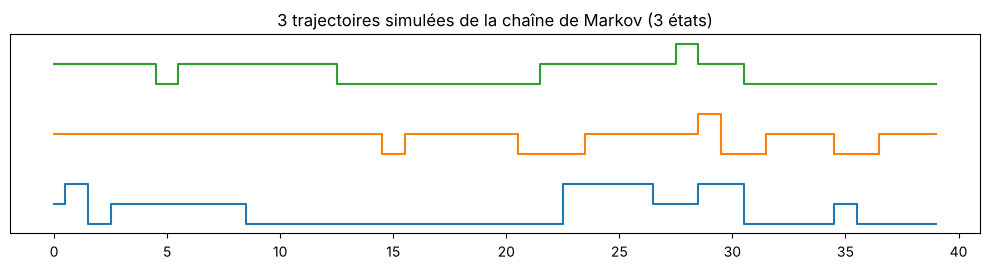

In [3]:
# d) simulation d'une chaîne de Markov : 3 trajectoires de 40 pas
rng = np.random.default_rng(1)
fig, ax = plt.subplots(figsize=(10, 2.8))
for r in range(3):
    s = [rng.choice(3, p=pi)]
    for _ in range(39):
        s.append(rng.choice(3, p=A[s[-1]]))
    ax.step(range(40), np.array(s) + r*3.5, where="mid")
ax.set_yticks([]); ax.set_title("3 trajectoires simulées de la chaîne de Markov (3 états)")
plt.tight_layout(); plt.show()

## 2. La séquence observée
On observe 6 rendements : **Hausse, Hausse, Baisse, Baisse, Baisse, Hausse**. Les régimes, eux, sont cachés.

In [4]:
O = np.array([0, 0, 1, 1, 1, 0])
T, N = len(O), len(pi)
print("Observations :", [OBS[o] for o in O])

Observations : ['Hausse', 'Hausse', 'Baisse', 'Baisse', 'Baisse', 'Hausse']


## 3. Forward : probabilité des observations
**α_t(i) = P(o_1…o_t, S_t = i)**
- Initialisation : `α_1(i) = π_i · b_i(o_1)`
- Récurrence : `α_t(j) = [ Σ_i α_{t-1}(i) · a_ij ] · b_j(o_t)`
- Résultat : `P(O | λ) = Σ_i α_T(i)`

In [5]:
alpha = np.zeros((T, N))
alpha[0] = pi * B[:, O[0]]
print(f"t=1  (obs={OBS[O[0]]}) : alpha = pi * b(o1) =", alpha[0])
for t in range(1, T):
    prediction = alpha[t-1] @ A                  # Sigma_i alpha_{t-1}(i) a_ij
    alpha[t] = prediction * B[:, O[t]]
    print(f"t={t+1}  (obs={OBS[O[t]]}) : alpha@A = {prediction}  ->  alpha = {alpha[t]}")

P_O = alpha[-1].sum()
print("\nP(O | lambda) =", P_O, "   log-vraisemblance =", np.log(P_O))

t=1  (obs=Hausse) : alpha = pi * b(o1) = [0.4  0.06 0.1 ]
t=2  (obs=Hausse) : alpha@A = [0.346 0.138 0.076]  ->  alpha = [0.2768 0.0276 0.038 ]
t=3  (obs=Baisse) : alpha@A = [0.2318 0.075  0.0356]  ->  alpha = [0.0464 0.06   0.0178]
t=4  (obs=Baisse) : alpha@A = [0.0466 0.0603 0.0172]  ->  alpha = [0.0093 0.0482 0.0086]
t=5  (obs=Baisse) : alpha@A = [0.014  0.0426 0.0096]  ->  alpha = [0.0028 0.0341 0.0048]
t=6  (obs=Hausse) : alpha@A = [0.0066 0.0291 0.0059]  ->  alpha = [0.0053 0.0058 0.003 ]

P(O | lambda) = 0.014078268100000008    log-vraisemblance = -4.263122940079248


## 4. Backward : l'information du futur
**β_t(i) = P(o_{t+1}…o_T | S_t = i)**
- Initialisation : `β_T(i) = 1`
- Récurrence : `β_t(i) = Σ_j a_ij · b_j(o_{t+1}) · β_{t+1}(j)`

In [6]:
beta = np.ones((T, N))
print(f"t={T}  : beta = 1 =", beta[-1])
for t in range(T-2, -1, -1):
    beta[t] = A @ (B[:, O[t+1]] * beta[t+1])
    print(f"t={t+1}  : beta =", beta[t])

# contrôle : P(O) se retrouve aussi avec beta
print("\nControle  sum_i pi_i b_i(o1) beta_1(i) =", (pi * B[:, O[0]] * beta[0]).sum())

t=6  : beta = 1 = [1. 1. 1.]
t=5  : beta = [0.695 0.29  0.47 ]
t=4  : beta = [0.1578 0.223  0.2149]
t=3  : beta = [0.0574 0.1566 0.1136]
t=2  : beta = [0.0308 0.1071 0.0683]
t=1  : beta = [0.0246 0.023  0.0284]

Controle  sum_i pi_i b_i(o1) beta_1(i) = 0.014078268100000006


## 5. Forward-Backward : probabilités a posteriori
**γ_t(i) = P(S_t = i | O) = α_t(i) β_t(i) / Σ_j α_t(j) β_t(j)** : « dans quel régime était-on à l'instant t ? »

In [7]:
gamma = alpha * beta
gamma = gamma / gamma.sum(axis=1, keepdims=True)
import pandas as pd
tab = pd.DataFrame(gamma, columns=ETATS, index=[f"t={t+1} ({OBS[O[t]]})" for t in range(T)])
tab["Régime le plus probable"] = [ETATS[i] for i in gamma.argmax(axis=1)]
display(tab.round(4))

,Haussier,Baissier,Panique,Régime le plus probable
t=1 (Hausse),0.7001,0.0981,0.2019,Haussier
t=2 (Hausse),0.6058,0.2099,0.1843,Haussier
t=3 (Baisse),0.1889,0.6675,0.1436,Baissier
t=4 (Baisse),0.1045,0.7640,0.1314,Baissier
t=5 (Baisse),0.1383,0.7015,0.1602,Baissier
t=6 (Hausse),0.3754,0.4135,0.2111,Baissier


## 6. Viterbi : la meilleure séquence d'états
- Initialisation : `δ_1(i) = π_i · b_i(o_1)`
- Récurrence : `δ_t(j) = max_i [ δ_{t-1}(i) · a_ij ] · b_j(o_t)` et `ψ_t(j) = argmax_i [ δ_{t-1}(i) · a_ij ]`
- Retour arrière : on part de `argmax δ_T` et on remonte avec ψ.

In [8]:
delta = np.zeros((T, N)); psi = np.zeros((T, N), dtype=int)
delta[0] = pi * B[:, O[0]]
print(f"t=1 : delta =", delta[0])
for t in range(1, T):
    cand = delta[t-1][:, None] * A                # cand[i,j] = delta_{t-1}(i) * a_ij
    psi[t] = cand.argmax(axis=0)
    delta[t] = cand.max(axis=0) * B[:, O[t]]
    print(f"t={t+1} : delta =", delta[t], "| psi =", [ETATS[i] for i in psi[t]])

chemin = [int(delta[-1].argmax())]
for t in range(T-1, 0, -1):
    chemin.append(int(psi[t, chemin[-1]]))
chemin = chemin[::-1]
print("\nChemin de Viterbi :", [ETATS[i] for i in chemin])
print("Probabilité du meilleur chemin :", delta[-1].max())

t=1 : delta = [0.4  0.06 0.1 ]
t=2 : delta = [0.256 0.012 0.025] | psi = ['Haussier', 'Haussier', 'Panique']
t=3 : delta = [0.041  0.0307 0.0064] | psi = ['Haussier', 'Haussier', 'Haussier']
t=4 : delta = [0.0066 0.0197 0.0016] | psi = ['Haussier', 'Baissier', 'Panique']
t=5 : delta = [0.001  0.0126 0.001 ] | psi = ['Haussier', 'Baissier', 'Baissier']
t=6 : delta = [0.001  0.002  0.0006] | psi = ['Baissier', 'Baissier', 'Baissier']

Chemin de Viterbi : ['Haussier', 'Haussier', 'Baissier', 'Baissier', 'Baissier', 'Baissier']
Probabilité du meilleur chemin : 0.0020132659200000013


## 7. Baum-Welch (EM) : apprendre π, A, B
À chaque itération :
- **E-step** : calculer `γ_t(i)` et `ξ_t(i,j) = P(S_t=i, S_{t+1}=j | O)` avec Forward-Backward.
- **M-step** : `π_i = γ_1(i)` · `a_ij = Σ_t ξ_t(i,j) / Σ_t γ_t(i)` · `b_i(k) = Σ_{t: o_t=k} γ_t(i) / Σ_t γ_t(i)`

La log-vraisemblance **ne peut pas diminuer** d'une itération à l'autre.

In [9]:
def forward_scale(O, pi, A, B):
    # Forward avec normalisation (scaling) : evite l'underflow sur de longues sequences
    T, N = len(O), len(pi); al = np.zeros((T, N)); c = np.zeros(T)
    al[0] = pi * B[:, O[0]]; c[0] = al[0].sum(); al[0] /= c[0]
    for t in range(1, T):
        al[t] = (al[t-1] @ A) * B[:, O[t]]; c[t] = al[t].sum(); al[t] /= c[t]
    return al, c                      # log P(O) = somme des log(c_t)

def backward_scale(O, A, B, c):
    T, N = len(O), A.shape[0]; be = np.ones((T, N))
    for t in range(T-2, -1, -1):
        be[t] = A @ (B[:, O[t+1]] * be[t+1]) / c[t+1]
    return be

def pas_baum_welch(O, pi, A, B):
    O = np.asarray(O); T, N = len(O), len(pi)
    al, c = forward_scale(O, pi, A, B); be = backward_scale(O, A, B, c)
    g = al * be                                                          # E-step : gamma
    xi = np.zeros((T-1, N, N))
    for t in range(T-1):                                                 # E-step : xi
        xi[t] = al[t][:, None] * A * (B[:, O[t+1]] * be[t+1])[None, :] / c[t+1]
    pi2 = g[0]                                                           # M-step
    A2  = xi.sum(axis=0) / g[:-1].sum(axis=0)[:, None]
    B2  = np.stack([g[O == k].sum(axis=0) for k in range(B.shape[1])], axis=1) / g.sum(axis=0)[:, None]
    return pi2, A2, B2, np.log(c).sum(), g, xi

def loglik(O, pi, A, B):
    return np.log(forward_scale(np.asarray(O), pi, A, B)[1]).sum()

# --- Itération n°1 en détail sur la petite séquence ---
pi1, A1, B1, ll0, g, xi = pas_baum_welch(O, pi, A, B)
print("log-vraisemblance avant :", ll0)
print("\nxi_1(i,j) = P(S_1=i, S_2=j | O) :\n", xi[0])
print("\nNouvelle A :\n", A1, "\nsomme des lignes :", A1.sum(axis=1))
print("\nNouvelle B :\n", B1)
print("\nNouveau pi :", pi1)

log-vraisemblance avant : -4.263122940079248

xi_1(i,j) = P(S_1=i, S_2=j | O) :
 [[0.5603 0.0913 0.0485]
 [0.0105 0.073  0.0145]
 [0.035  0.0456 0.1212]]

Nouvelle A :
 [[0.5899 0.3326 0.0776]
 [0.1095 0.7787 0.1118]
 [0.147  0.3382 0.5148]] 
somme des lignes : [1. 1. 1.]

Nouvelle B :
 [[0.7957 0.2043]
 [0.2527 0.7473]
 [0.5785 0.4215]]

Nouveau pi : [0.7001 0.0981 0.2019]


In [10]:
# --- 5 itérations successives sur la petite séquence ---
p, a, b = pi.copy(), A.copy(), B.copy()
for it in range(1, 6):
    p, a, b, ll, _, _ = pas_baum_welch(O, p, a, b)
    print(f"itération {it} : log-vraisemblance avant mise à jour = {ll:.4f}")
print("\nAttention : avec seulement 6 observations le modèle sur-apprend (probabilités proches de 0 ou 1).")
print("Pour de vrais résultats, il faut beaucoup d'observations -> exemple suivant.")

itération 1 : log-vraisemblance avant mise à jour = -4.2631
itération 2 : log-vraisemblance avant mise à jour = -3.7077
itération 3 : log-vraisemblance avant mise à jour = -3.4776
itération 4 : log-vraisemblance avant mise à jour = -3.3364
itération 5 : log-vraisemblance avant mise à jour = -3.2579

Attention : avec seulement 6 observations le modèle sur-apprend (probabilités proches de 0 ou 1).
Pour de vrais résultats, il faut beaucoup d'observations -> exemple suivant.


### Baum-Welch sur une longue séquence simulée
⚠️ Sur une longue séquence, les produits de probabilités deviennent **trop petits pour l'ordinateur** (underflow, on obtient `nan`). On utilise donc la version **avec normalisation (scaling)** : à chaque pas on divise α par sa somme `c_t`, et `log P(O) = Σ log c_t`. C'est ce que font `hmmlearn` et tous les logiciels sérieux.

On simule 2000 observations avec le **vrai** modèle (π, A, B), puis on part d'un modèle **aléatoire** et on regarde la convergence. Les états appris peuvent être dans un autre ordre (permutation des étiquettes) : c'est normal.

itération   1 : log-vraisemblance = -1385.612
itération   2 : log-vraisemblance = -1383.351
itération   3 : log-vraisemblance = -1383.302
itération   5 : log-vraisemblance = -1383.224


itération  10 : log-vraisemblance = -1383.094


itération  20 : log-vraisemblance = -1382.863


itération  50 : log-vraisemblance = -1320.022


itération 100 : log-vraisemblance = -1317.200

Vérification que la log-vraisemblance ne diminue jamais : True


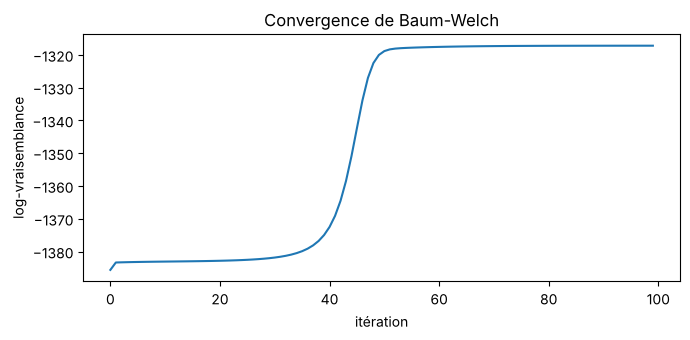

A apprise :
 [[0.4388 0.0918 0.4694]
 [0.0438 0.7783 0.1779]
 [0.4485 0.2554 0.2961]]
B apprise :
 [[0.1171 0.8829]
 [0.8039 0.1961]
 [0.29   0.71  ]]


In [11]:
def simuler(T, pi, A, B, seed=0):
    rng = np.random.default_rng(seed)
    S = np.zeros(T, int); X = np.zeros(T, int)
    S[0] = rng.choice(len(pi), p=pi); X[0] = rng.choice(B.shape[1], p=B[S[0]])
    for t in range(1, T):
        S[t] = rng.choice(len(pi), p=A[S[t-1]]); X[t] = rng.choice(B.shape[1], p=B[S[t]])
    return S, X

S_vrai, X = simuler(2000, pi, A, B, seed=42)

rng = np.random.default_rng(7)
def alea(*shape):
    M = rng.random(shape) + 0.5
    return M / M.sum(axis=-1, keepdims=True)
p, a, b = alea(3), alea(3, 3), alea(3, 2)
p0, a0, b0 = p.copy(), a.copy(), b.copy()

historique = []
for it in range(1, 101):
    p, a, b, ll, _, _ = pas_baum_welch(X, p, a, b)
    historique.append(ll)
    if it in (1, 2, 3, 5, 10, 20, 50, 100):
        print(f"itération {it:3d} : log-vraisemblance = {ll:.3f}")

print("\nVérification que la log-vraisemblance ne diminue jamais :", all(np.diff(historique) > -1e-9))
plt.figure(figsize=(7, 3.5)); plt.plot(historique)
plt.xlabel("itération"); plt.ylabel("log-vraisemblance"); plt.title("Convergence de Baum-Welch")
plt.tight_layout(); plt.show()
print("A apprise :\n", a); print("B apprise :\n", b)

## 8. Vérification avec `hmmlearn`
Les valeurs de `hmmlearn` doivent être **les mêmes** que celles calculées à la main (score, états de Viterbi, probabilités γ).

In [12]:
from hmmlearn.hmm import CategoricalHMM

m = CategoricalHMM(n_components=3, n_features=2, init_params="")
m.startprob_, m.transmat_, m.emissionprob_ = pi, A, B
Xc = O.reshape(-1, 1)

print("log P(O) hmmlearn :", m.score(Xc), "| à la main :", np.log(P_O))
print("Viterbi hmmlearn  :", m.predict(Xc), "| à la main :", np.array(chemin))
print("gamma identiques  :", np.allclose(m.predict_proba(Xc), gamma))

# Baum-Welch : hmmlearn et ma version, MEME initialisation (p0, a0, b0), 100 itérations
m2 = CategoricalHMM(n_components=3, n_features=2, n_iter=100, tol=1e-12, init_params="")
m2.startprob_, m2.transmat_, m2.emissionprob_ = p0.copy(), a0.copy(), b0.copy()
m2.fit(X.reshape(-1, 1))
print("log-vraisemblance finale hmmlearn :", m2.score(X.reshape(-1, 1)))
print("log-vraisemblance finale (à la main):", loglik(X, p, a, b))
print("Même matrice A apprise :", np.allclose(m2.transmat_, a, atol=1e-4))

# Pourquoi lancer plusieurs initialisations : optimum local
print("\nlog-vraisemblance du VRAI modèle sur ces données :", loglik(X, pi, A, B))
scores = []
for seed in range(10):
    mm = CategoricalHMM(n_components=3, n_features=2, n_iter=300, tol=1e-6, random_state=seed)
    mm.fit(X.reshape(-1, 1)); scores.append(mm.score(X.reshape(-1, 1)))
print("10 initialisations aléatoires :", np.round(scores, 1))
print("-> on garde la meilleure (la plus grande log-vraisemblance)")

log P(O) hmmlearn : -4.263122940079248 | à la main : -4.263122940079248
Viterbi hmmlearn  : [0 0 1 1 1 1] | à la main : [0 0 1 1 1 1]
gamma identiques  : True
log-vraisemblance finale hmmlearn : -1317.1991342677918
log-vraisemblance finale (à la main): -1317.1991342677502
Même matrice A apprise : True

log-vraisemblance du VRAI modèle sur ces données : -1319.0024199442603


10 initialisations aléatoires : [-1383.  -1317.1 -1317.2 -1315.2 -1383.  -1317.2 -1317.3 -1317.3 -1317.2
 -1315.5]
-> on garde la meilleure (la plus grande log-vraisemblance)


## 9. Lien avec le projet : rendements et prédiction du prochain régime
Dans le projet, l'observation sera le **rendement log** (et la volatilité) d'une bougie de 8 h. Ici, version simplifiée : Hausse / Baisse.

**Prédiction à un pas** : `P(S_{t+1}) = γ_t · A`, où γ_t est la probabilité *filtrée* (qui n'utilise que le passé).

In [13]:
# Probabilité filtrée P(S_t | o_1..o_t) : forward normalisé (n'utilise QUE le passé)
filtre = alpha / alpha.sum(axis=1, keepdims=True)
print("Probabilités filtrées au dernier instant :", dict(zip(ETATS, filtre[-1].round(4))))

# Prédiction du régime à t+1
prochain = filtre[-1] @ A
print("Prédiction P(S_{T+1}) :", dict(zip(ETATS, prochain.round(4))))
print("Régime le plus probable demain :", ETATS[prochain.argmax()])

# Prédiction de l'observation suivante : P(o_{T+1}) = P(S_{T+1}) · B
print("P(prochain rendement) :", dict(zip(OBS, (prochain @ B).round(4))))

# Prédiction à k pas : on multiplie par A^k, et on tend vers la distribution stationnaire
for k in [1, 2, 5, 20]:
    print(f"k={k:2d} :", (filtre[-1] @ np.linalg.matrix_power(A, k)).round(4))

Probabilités filtrées au dernier instant : {'Haussier': np.float64(0.3754), 'Baissier': np.float64(0.4135), 'Panique': np.float64(0.2111)}
Prédiction P(S_{T+1}) : {'Haussier': np.float64(0.3839), 'Baissier': np.float64(0.4504), 'Panique': np.float64(0.1657)}
Régime le plus probable demain : Baissier
P(prochain rendement) : {'Hausse': np.float64(0.48), 'Baisse': np.float64(0.52)}
k= 1 : [0.3839 0.4504 0.1657]
k= 2 : [0.3853 0.4676 0.1471]
k= 5 : [0.3818 0.4827 0.1355]
k=20 : [0.3784 0.4865 0.1351]
